# DAML Homework 4 — Searchlight
## From pixels to attention

A search-and-rescue drone has recorded five tiny grayscale frames. Your job is to build a miniature neural pipeline that:

1. **projects** features with an MLP-style affine layer,
2. **extracts local patterns** with convolution,
3. **summarizes** feature maps with pooling, and
4. **attends** to the observations that match a query while respecting a causal mask.

**Required section:** approximately 40–45 minutes  
**Optional deep dive:** approximately 45–90+ minutes  
**Required score:** 100 points = 95 autograded + 5 manually graded

<div style="border-left: 5px solid #2563eb; padding: 0.85em 1em; background: #eff6ff;">
<b>How this notebook helps you:</b> every required function is preceded by a worked example, a shape recipe, and a public check. Most TODOs are one to four lines. The full data pipeline and visualizations are supplied.
</div>

### Learning objectives

By the end, you should be able to:

- trace shapes through $$Z = XW + b,$$
- explain why a CNN reuses one local kernel across an image,
- implement valid 2D convolution and average pooling,
- construct $$Q,$$ $$K,$$ and $$V$$ with learned projections,
- implement scaled dot-product attention,
- explain why a causal mask blocks future positions.

## Working policy: make a real attempt first

You may use AI tools for explanations, hints, and debugging **after a fair initial attempt**. You must understand every submitted line. Complete the assistance disclosure near the end of the notebook; this disclosure is ungraded.

## Submission contract

- Submit exactly one notebook named `DAML_HW04_Searchlight.ipynb`.
- Keep all required function names and signatures unchanged.
- Use only NumPy and Matplotlib in the required section.
- Before submitting, choose **Runtime → Restart session and run all** in Colab.
- Confirm every required public check passes.
- Do not submit the primer, Exploration Studio, a PDF, an HTML export, or a ZIP.

In [137]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 120

# Mission setup

Each frame is a $$7\times 7$$ image. Some frames contain a mostly vertical beacon, some contain a horizontal beacon, and one contains a cross. The labels below are only for the story and plots—the pipeline itself will work from the pixel values.

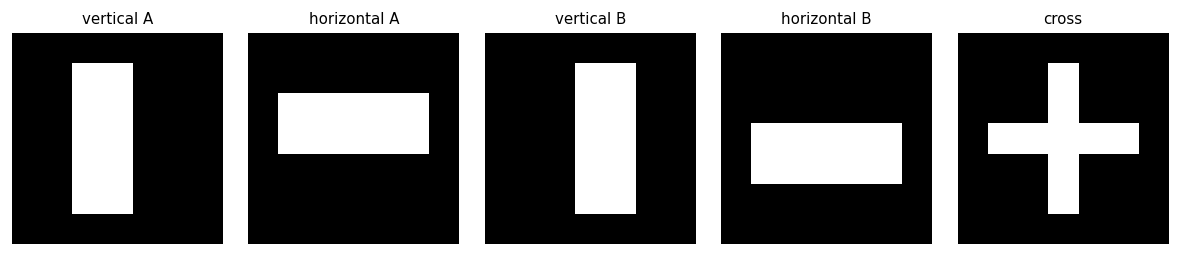

In [138]:
FRAME_NAMES = [
    "vertical A",
    "horizontal A",
    "vertical B",
    "horizontal B",
    "cross",
]

def make_frame(kind, shift=0):
    image = np.zeros((7, 7), dtype=float)
    if kind == "vertical":
        image[1:6, 2 + shift : 4 + shift] = 1.0
    elif kind == "horizontal":
        image[2 + shift : 4 + shift, 1:6] = 1.0
    elif kind == "cross":
        image[1:6, 3] = 1.0
        image[3, 1:6] = 1.0
    else:
        raise ValueError("unknown frame kind")
    return image

FRAMES = np.stack([
    make_frame("vertical", 0),
    make_frame("horizontal", 0),
    make_frame("vertical", 1),
    make_frame("horizontal", 1),
    make_frame("cross"),
])

fig, axes = plt.subplots(1, len(FRAMES), figsize=(10, 2.1))
for ax, frame, name in zip(axes, FRAMES, FRAME_NAMES):
    ax.imshow(frame, cmap="gray", vmin=0, vmax=1)
    ax.set_title(name, fontsize=9)
    ax.axis("off")
plt.tight_layout()

# Part 1 — An MLP layer as a learned projection (15 points, ~6 minutes)

The lecture wrote a hidden layer as:

$$
Z = XW + b
$$

If $$X$$ has shape $$(m,n)$$ and the hidden width is $$h$$, then:

| object | shape |
|---|---|
| $$X$$ | $$(m,n)$$ |
| $$W$$ | $$(n,h)$$ |
| $$b$$ | $$(h,)$$ |
| $$Z$$ | $$(m,h)$$ |

NumPy broadcasts the one-dimensional bias across all $$m$$ rows.

In [139]:
# Worked example — inspect the shapes before writing the function.
X_demo = np.array([[1.0, 2.0], [3.0, 4.0]])
W_demo = np.array([[1.0, -1.0, 0.5], [0.0, 2.0, 1.0]])
b_demo = np.array([0.5, 1.0, -1.0])

print("X shape:", X_demo.shape)
print("W shape:", W_demo.shape)
print("b shape:", b_demo.shape)
print("Expected output shape: (2, 3)")

X shape: (2, 2)
W shape: (2, 3)
b shape: (3,)
Expected output shape: (2, 3)


In [140]:
def affine_projection(X, W, b):
    """Return the affine projection X @ W + b.

    Shapes
    ------
    X : (num_items, input_features)
    W : (input_features, hidden_features)
    b : (hidden_features,)
    """
    X = np.asarray(X, dtype=float)
    W = np.asarray(W, dtype=float)
    b = np.asarray(b, dtype=float)

    if X.ndim != 2 or W.ndim != 2 or b.ndim != 1:
        raise ValueError("X and W must be 2D, and b must be 1D")
    if X.shape[1] != W.shape[0] or W.shape[1] != b.shape[0]:
        raise ValueError("The inner and hidden dimensions must agree")

    # TODO: one matrix multiplication plus one broadcasted addition.
    return X @ W + b
    raise NotImplementedError("Complete affine_projection")

In [141]:
expected = np.array([[1.5, 4.0, 1.5], [3.5, 6.0, 4.5]])
actual = affine_projection(X_demo, W_demo, b_demo)
assert actual.shape == (2, 3)
assert np.allclose(actual, expected)
print("✓ affine_projection passed the public check")

✓ affine_projection passed the public check


## 1B. ReLU (5 points)

ReLU keeps positive values and sets negative values to zero:

$$
\operatorname{ReLU}(z)=\max(0,z)
$$

In [142]:
def relu(Z):
    """Apply ReLU elementwise without modifying the input."""
    Z = np.asarray(Z, dtype=float)



    # TODO: keep positive entries and replace negative entries with zero.
    return np.maximum(0, Z)

In [143]:
relu_demo = np.array([[-2.0, 0.0, 3.0], [4.0, -1.0, 2.0]])
assert np.array_equal(relu(relu_demo), np.array([[0.0, 0.0, 3.0], [4.0, 0.0, 2.0]]))
print("✓ relu passed the public check")

✓ relu passed the public check


# Part 2 — CNN feature extraction: select, then summarize (30 points, ~13 minutes)

A fully connected layer treats every input coordinate separately. A convolutional layer instead:

- looks at a **local patch**,
- uses the **same kernel weights** at every location, and
- produces a feature map showing where a pattern appears.

We use the neural-network convention commonly called convolution: multiply a patch by the kernel **without flipping the kernel**, then sum.

## 2A. Valid 2D convolution (18 points)

For an image with shape $$(H,W)$$ and a kernel with shape $$(K_H,K_W)$$, valid convolution produces:

$$
(H-K_H+1,\;W-K_W+1)
$$

**Recipe for one output location**

1. Slice the matching image patch.
2. Multiply the patch and kernel elementwise.
3. Sum all products.

In [144]:
image_worked = np.array([
    [1.0, 2.0, 0.0],
    [0.0, 1.0, 3.0],
    [2.0, 1.0, 0.0],
])
kernel_worked = np.array([
    [1.0, 0.0],
    [0.0, -1.0],
])
first_patch = image_worked[:2, :2]
print("First patch:\n", first_patch)
print("Patch × kernel:\n", first_patch * kernel_worked)
print("First output value:", np.sum(first_patch * kernel_worked))

First patch:
 [[1. 2.]
 [0. 1.]]
Patch × kernel:
 [[ 1.  0.]
 [ 0. -1.]]
First output value: 0.0


In [145]:
def conv2d_valid(image, kernel):
    """Apply a 2D kernel wherever it fits completely inside the image.

    This is the cross-correlation operation commonly called "convolution"
    in neural-network libraries: do not flip the kernel.
    """
    image = np.asarray(image, dtype=float)
    kernel = np.asarray(kernel, dtype=float)

    if image.ndim != 2 or kernel.ndim != 2:
        raise ValueError("image and kernel must both be 2D")
    if kernel.size == 0 or kernel.shape[0] > image.shape[0] or kernel.shape[1] > image.shape[1]:
        raise ValueError("kernel must be nonempty and fit inside the image")

    out_h = image.shape[0] - kernel.shape[0] + 1
    out_w = image.shape[1] - kernel.shape[1] + 1
    output = np.empty((out_h, out_w), dtype=float)

    for row in range(out_h):
        for col in range(out_w):
            patch = image[
                row : row + kernel.shape[0],
                col : col + kernel.shape[1],
            ]
            # TODO: replace np.nan with the patch–kernel dot product.
            output[row, col] = np.sum(patch*kernel)
    return output

In [146]:
expected = np.array([[0.0, -1.0], [-1.0, 1.0]])
actual = conv2d_valid(image_worked, kernel_worked)
assert actual.shape == (2, 2)
assert np.allclose(actual, expected)
print("✓ conv2d_valid passed the public check")

✓ conv2d_valid passed the public check


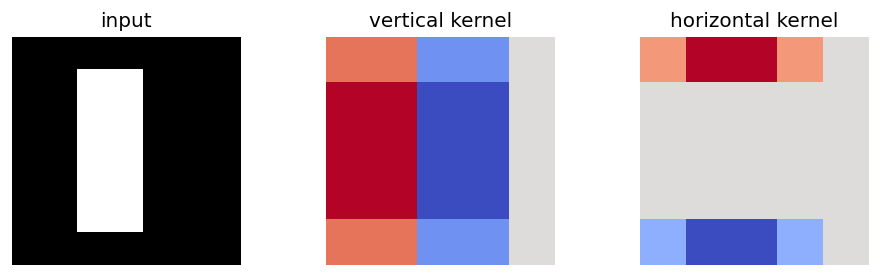

In [147]:
VERTICAL_KERNEL = np.array([
    [-1.0, 0.0, 1.0],
    [-1.0, 0.0, 1.0],
    [-1.0, 0.0, 1.0],
])
HORIZONTAL_KERNEL = np.array([
    [-1.0, -1.0, -1.0],
    [ 0.0,  0.0,  0.0],
    [ 1.0,  1.0,  1.0],
])

vertical_map = conv2d_valid(FRAMES[0], VERTICAL_KERNEL)
horizontal_map = conv2d_valid(FRAMES[0], HORIZONTAL_KERNEL)

fig, axes = plt.subplots(1, 3, figsize=(8, 2.4))
axes[0].imshow(FRAMES[0], cmap="gray", vmin=0, vmax=1)
axes[0].set_title("input")
axes[1].imshow(vertical_map, cmap="coolwarm")
axes[1].set_title("vertical kernel")
axes[2].imshow(horizontal_map, cmap="coolwarm")
axes[2].set_title("horizontal kernel")
for ax in axes:
    ax.axis("off")
plt.tight_layout()

## 2B. Average pooling (12 points)

Convolution **selects** local patterns. Pooling **summarizes** nearby responses.

For each pooling window, calculate its mean. With a $$2\times2$$ window and stride 2, a $$4\times4$$ map becomes $$2\times2$$.

In [148]:
def avg_pool2d(feature_map, pool_size=2, stride=2):
    """Average each pool_size × pool_size window using the given stride."""
    feature_map = np.asarray(feature_map, dtype=float)

    if feature_map.ndim != 2:
        raise ValueError("feature_map must be 2D")
    if not isinstance(pool_size, (int, np.integer)) or not isinstance(stride, (int, np.integer)):
        raise ValueError("pool_size and stride must be integers")
    if pool_size <= 0 or stride <= 0:
        raise ValueError("pool_size and stride must be positive")
    if pool_size > feature_map.shape[0] or pool_size > feature_map.shape[1]:
        raise ValueError("pooling window must fit inside the feature map")

    out_h = 1 + (feature_map.shape[0] - pool_size) // stride
    out_w = 1 + (feature_map.shape[1] - pool_size) // stride
    pooled = np.empty((out_h, out_w), dtype=float)

    for row in range(out_h):
        for col in range(out_w):
            window = feature_map[
                row * stride : row * stride + pool_size,
                col * stride : col * stride + pool_size,
            ]
            # TODO: replace np.nan with the mean of this window.
            pooled[row, col] = np.mean(window)

    return pooled

In [149]:
pool_demo = np.array([
    [1.0, 3.0, 2.0, 4.0],
    [5.0, 7.0, 6.0, 8.0],
    [2.0, 4.0, 1.0, 3.0],
    [6.0, 8.0, 5.0, 7.0],
])
expected = np.array([[4.0, 5.0], [5.0, 4.0]])
assert np.allclose(avg_pool2d(pool_demo, pool_size=2, stride=2), expected)
print("✓ avg_pool2d passed the public check")

✓ avg_pool2d passed the public check


In [150]:
def frame_to_features(frame):
    vertical = avg_pool2d(np.abs(conv2d_valid(frame, VERTICAL_KERNEL)))
    horizontal = avg_pool2d(np.abs(conv2d_valid(frame, HORIZONTAL_KERNEL)))
    return np.array([
        vertical.mean(),
        horizontal.mean(),
        frame.mean(),
    ])

FRAME_FEATURES = np.vstack([frame_to_features(frame) for frame in FRAMES])
print("Rows are frames; columns are [vertical-edge strength, horizontal-edge strength, brightness].")
print(FRAME_FEATURES)

W_HIDDEN = np.array([
    [1.0, 0.0, 0.0, 0.5],
    [0.0, 1.0, 0.0, 0.5],
    [0.0, 0.0, 4.0, 0.0],
])
B_HIDDEN = np.array([0.0, 0.0, -0.5, 0.0])
HIDDEN = relu(affine_projection(FRAME_FEATURES, W_HIDDEN, B_HIDDEN))
print("\nProjected hidden representations, shape", HIDDEN.shape)
print(HIDDEN)

Rows are frames; columns are [vertical-edge strength, horizontal-edge strength, brightness].
[[2.75  0.375 0.204]
 [0.375 2.75  0.204]
 [2.062 0.312 0.204]
 [0.312 2.062 0.204]
 [1.188 1.188 0.184]]

Projected hidden representations, shape (5, 4)
[[2.75  0.375 0.316 1.562]
 [0.375 2.75  0.316 1.562]
 [2.062 0.312 0.316 1.188]
 [0.312 2.062 0.316 1.188]
 [1.188 1.188 0.235 1.188]]


# Part 3 — Query, key, value, and attention (50 points, ~20 minutes)

Attention asks a content-dependent question:

- a **query** says what we are looking for,
- a **key** says what each item contains,
- a **value** says what information to retrieve.

The lecture constructs them using learned linear transformations:

$$
Q=XW_Q,\qquad K=XW_K,\qquad V=XW_V
$$

## 3A. Project to $$Q$$, $$K$$, and $$V$$ (10 points)

If $$X$$ has shape $$(n,d_{model})$$:

- $$W_Q$$ and $$W_K$$ map to $$d_k$$,
- $$W_V$$ maps to $$d_v$$.

In [151]:
def project_qkv(X, W_q, W_k, W_v):
    """Create queries, keys, and values with learned linear projections."""
    X = np.asarray(X, dtype=float)
    W_q = np.asarray(W_q, dtype=float)
    W_k = np.asarray(W_k, dtype=float)
    W_v = np.asarray(W_v, dtype=float)

    if X.ndim != 2 or any(W.ndim != 2 for W in (W_q, W_k, W_v)):
        raise ValueError("X and all projection matrices must be 2D")
    if any(W.shape[0] != X.shape[1] for W in (W_q, W_k, W_v)):
        raise ValueError("Every projection matrix must accept X's feature dimension")
    if W_q.shape[1] != W_k.shape[1]:
        raise ValueError("queries and keys must have the same feature dimension")

    # TODO: compute the three matrix products.
    Q = X @ W_q
    K = X @ W_k
    V = X @ W_v

    return Q,K,V

    raise NotImplementedError("Complete project_qkv")

In [152]:
X_qkv = np.array([[1.0, 2.0], [3.0, 4.0]])
W_q_demo = np.array([[1.0, 0.0], [0.0, 1.0]])
W_k_demo = np.array([[2.0, 0.0], [0.0, 0.5]])
W_v_demo = np.array([[1.0], [-1.0]])
Q_demo, K_demo, V_demo = project_qkv(X_qkv, W_q_demo, W_k_demo, W_v_demo)
assert np.allclose(Q_demo, X_qkv)
assert np.allclose(K_demo, np.array([[2.0, 1.0], [6.0, 2.0]]))
assert np.allclose(V_demo, np.array([[-1.0], [-1.0]]))
print("✓ project_qkv passed the public check")

✓ project_qkv passed the public check


## 3B. Stable row-wise softmax (10 points)

Softmax turns score logits into nonnegative weights that sum to 1:

$$
\alpha_i=\frac{e^{e_i}}{\sum_j e^{e_j}}
$$

Directly computing `np.exp(1000)` overflows. The stable version subtracts each row maximum first; this does not change the final probabilities.

In [153]:
scores_worked = np.array([[1000.0, 1001.0], [2.0, 2.0]])
shifted_worked = scores_worked - scores_worked.max(axis=1, keepdims=True)
print("Shifted scores:\n", shifted_worked)
print("No large positive exponent remains.")

Shifted scores:
 [[-1.  0.]
 [ 0.  0.]]
No large positive exponent remains.


In [154]:
def row_softmax(scores):
    """Compute a numerically stable softmax across each row."""
    scores = np.asarray(scores, dtype=float)
    if scores.ndim != 2:
        raise ValueError("scores must be a 2D matrix")
    if np.any(np.all(np.isneginf(scores), axis=1)):
        raise ValueError("each row must contain at least one allowed finite score")

    subtracted_scores = scores - np.max(scores, axis=1, keepdims=True)

    exp_scores = np.exp(subtracted_scores)

    normalized_scores = exp_scores / np.sum(exp_scores, axis=1, keepdims=True)

    return normalized_scores

In [155]:
softmax_result = row_softmax(scores_worked)
assert np.all(np.isfinite(softmax_result))
assert np.allclose(softmax_result.sum(axis=1), 1.0)
assert np.allclose(softmax_result[1], np.array([0.5, 0.5]))
print("✓ row_softmax passed the public check")

✓ row_softmax passed the public check


## 3C. Causal mask (10 points)

During left-to-right generation, position $$t$$ may use the current and past positions, but it cannot peek at future positions.

Add this mask **before softmax**:

- allowed entry: $$0$$
- blocked entry: $$-\infty$$

Exponentiating a blocked score then gives weight 0.

In [156]:
def causal_mask(length):
    """Return a mask with 0 for current/past positions and -inf for the future."""
    if not isinstance(length, (int, np.integer)) or length <= 0:
        raise ValueError("length must be a positive integer")

    mask = np.zeros((length, length), dtype=float)
    future_positions = np.triu(np.ones((length, length), dtype=bool), k=1)


    # TODO: blocked future positions must become negative infinity.
    mask[future_positions] = -np.inf
    return mask

In [157]:
expected_mask = np.array([
    [0.0, -np.inf, -np.inf],
    [0.0, 0.0, -np.inf],
    [0.0, 0.0, 0.0],
])
assert np.array_equal(causal_mask(3), expected_mask)
print("✓ causal_mask passed the public check")

✓ causal_mask passed the public check


## 3D. Scaled dot-product attention (20 points)

The complete matrix equation is:

$$
\operatorname{Attention}(Q,K,V)
=\operatorname{softmax}\left(\frac{QK^T}{\sqrt{d_k}}+M\right)V
$$

| object | shape |
|---|---|
| $$Q$$ | $$(n_q,d_k)$$ |
| $$K^T$$ | $$(d_k,n_k)$$ |
| scores / weights | $$(n_q,n_k)$$ |
| $$V$$ | $$(n_k,d_v)$$ |
| output | $$(n_q,d_v)$$ |

Dividing by $$\sqrt{d_k}$$ keeps dot-product scores from growing too sharply as the key dimension increases.

In [158]:
# The numerical example from lecture:
q_lecture = np.array([[np.sqrt(2.0), 0.0]])
K_lecture = np.array([[1.0, 0.0], [0.0, 1.0]])
V_lecture = np.array([[2.0, 0.0], [0.0, 4.0]])
print("Expected attention weights are approximately [0.731, 0.269].")

Expected attention weights are approximately [0.731, 0.269].


In [159]:
def scaled_dot_product_attention(Q, K, V, mask=None):
    """Return (output, attention_weights) for scaled dot-product attention."""
    Q = np.asarray(Q, dtype=float)
    K = np.asarray(K, dtype=float)
    V = np.asarray(V, dtype=float)

    if Q.ndim != 2 or K.ndim != 2 or V.ndim != 2:
        raise ValueError("Q, K, and V must all be 2D")
    if Q.shape[1] != K.shape[1]:
        raise ValueError("Q and K must share the same key dimension")
    if K.shape[0] != V.shape[0]:
        raise ValueError("K and V must contain the same number of items")

    # TODO 1: compare every query with every key and divide by sqrt(d_k).
    d_k = Q.shape[1]
    scores = (Q @ K.T) / np.sqrt(d_k)

    if mask is not None:
        mask = np.asarray(mask, dtype=float)
        if mask.shape != scores.shape:
            raise ValueError("mask must have shape (num_queries, num_keys)")
        scores = scores + mask

    # TODO 2: normalize each row into attention weights.
    weights = row_softmax(scores)

    # TODO 3: use the weights to take a weighted sum of the values.
    output = weights @ V

    return output, weights

In [160]:
output_lecture, weights_lecture = scaled_dot_product_attention(
    q_lecture, K_lecture, V_lecture
)
assert np.allclose(weights_lecture, np.array([[0.73105858, 0.26894142]]))
assert np.allclose(output_lecture, np.array([[1.46211716, 1.07576569]]))
print("✓ scaled_dot_product_attention passed the public check")

✓ scaled_dot_product_attention passed the public check


## Put the pipeline together — provided synthesis

First, self-attention lets each frame compare itself with the other frame representations. The causal mask ensures frame $$t$$ cannot read a later frame.

Each row sums to 1, and every future-position weight is 0.


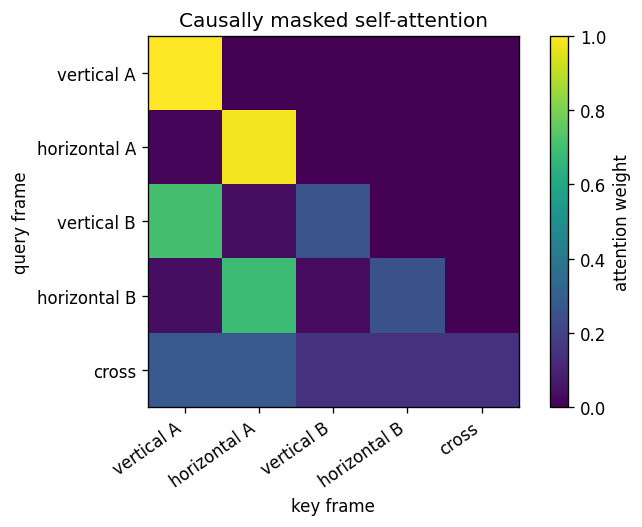

In [161]:
W_Q = np.array([
    [1.0, 0.0],
    [0.0, 1.0],
    [0.0, 0.0],
    [0.0, 0.0],
])
W_K = W_Q.copy()
W_V = np.array([
    [0.3, 0.0, 0.2],
    [0.0, 0.3, 0.2],
    [0.0, 0.0, 1.0],
    [0.2, 0.2, 0.0],
])

Q, K, V = project_qkv(HIDDEN, W_Q, W_K, W_V)
MASK = causal_mask(len(FRAMES))
ATTENDED, ATTENTION_WEIGHTS = scaled_dot_product_attention(Q, K, V, mask=MASK)

fig, ax = plt.subplots(figsize=(6.2, 4.5))
image = ax.imshow(ATTENTION_WEIGHTS, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(FRAME_NAMES)), FRAME_NAMES, rotation=35, ha="right")
ax.set_yticks(range(len(FRAME_NAMES)), FRAME_NAMES)
ax.set_xlabel("key frame")
ax.set_ylabel("query frame")
ax.set_title("Causally masked self-attention")
fig.colorbar(image, ax=ax, label="attention weight")
plt.tight_layout()

assert np.allclose(ATTENTION_WEIGHTS.sum(axis=1), 1.0)
assert np.allclose(np.triu(ATTENTION_WEIGHTS, k=1), 0.0)
print("Each row sums to 1, and every future-position weight is 0.")

### Same keys and values, different query

A query for a vertical edge and a query for a horizontal edge inspect the **same** keys and values but should retrieve different frames.

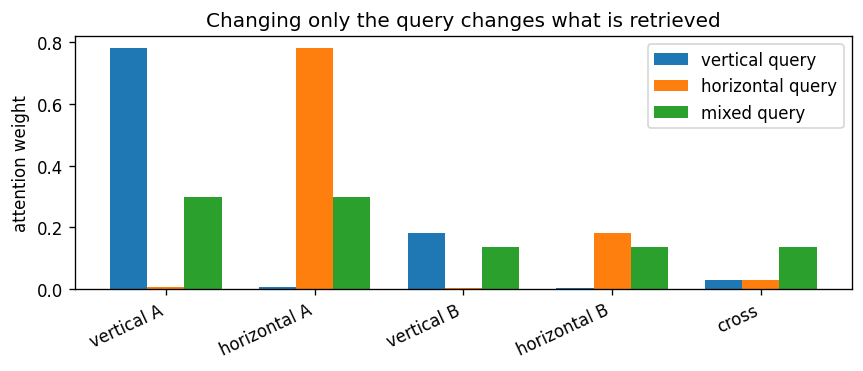

In [162]:
SEARCH_QUERIES = np.array([
    [3.0, 0.0],   # seek a vertical pattern
    [0.0, 3.0],   # seek a horizontal pattern
    [1.5, 1.5],   # seek a mixed pattern
])
SEARCH_NAMES = ["vertical query", "horizontal query", "mixed query"]
SEARCH_OUTPUTS, SEARCH_WEIGHTS = scaled_dot_product_attention(SEARCH_QUERIES, K, V)

fig, ax = plt.subplots(figsize=(7.3, 3.2))
x = np.arange(len(FRAME_NAMES))
width = 0.25
for index, (name, weights) in enumerate(zip(SEARCH_NAMES, SEARCH_WEIGHTS)):
    ax.bar(x + (index - 1) * width, weights, width=width, label=name)
ax.set_xticks(x, FRAME_NAMES, rotation=25, ha="right")
ax.set_ylabel("attention weight")
ax.set_title("Changing only the query changes what is retrieved")
ax.legend()
plt.tight_layout()

# Part 4 — Interpret the machinery (5 points, ~5 minutes)

Write **4–6 sentences** that answer all three prompts:

1. How does a convolution kernel decide what information matters, and how is that different from an attention query?
2. Why is the causal mask necessary for left-to-right generation? Refer to the attention heatmap.
3. What information can average pooling discard even when it makes the representation smaller and easier to use?

A convolution kernel determines the important information by learning local weights during training. On the other hand, attention queries determine what information matters by creating matching scores between the query and the target key vectors. Causal maps are necessary for left-to-right generation because the softmax function sets the attention weight of fuutre positions to zero, which can be seen by the dark upper triangle on the attention heatmap. Average pooling summarizes information and compresses a 4x4 matrix into a 2x2 matrix. This means is discards the exact spatial position and structural layout information of the features in favor of smaller and easier tomanage representation sizes.



## Submission checklist

- [ ] Every required public check passes.
- [ ] The notebook runs from a fresh runtime.
- [ ] The interpretation response is complete.
- [ ] The assistance disclosure is complete.
- [ ] The file is named `DAML_HW04_Searchlight.ipynb`.

**Disclosure:** None / replace with a brief note about people, AI tools, or other substantial help used.

# Optional Deep Dive — Padding, confidence, and multiple heads

These extensions are not required. They are worth up to **10 bonus points** in total.

In [163]:
RUN_BONUS_A = False
RUN_BONUS_B = False
RUN_BONUS_C = False

## Bonus A — “Same” convolution (3 points)

Zero-pad an odd-sized kernel so the output has the same height and width as the input image.

In [164]:
def conv2d_same(image, kernel):
    """Bonus: zero-pad an odd-sized kernel so output has the image's shape."""
    image = np.asarray(image, dtype=float)
    kernel = np.asarray(kernel, dtype=float)
    # TODO
    raise NotImplementedError("Complete conv2d_same")

In [165]:
if RUN_BONUS_A:
    bonus_image = np.arange(16, dtype=float).reshape(4, 4)
    bonus_kernel = np.ones((3, 3))
    same = conv2d_same(bonus_image, bonus_kernel)
    assert same.shape == bonus_image.shape
    print("✓ Bonus A public check passed")

## Bonus B — Attention entropy (3 points)

Entropy is small when a query concentrates on a few keys and large when its weight is spread broadly:

$$
H(\alpha)=-\sum_i \alpha_i\log\alpha_i
$$

In [166]:
def attention_entropy(weights, epsilon=1e-12):
    """Bonus: return one Shannon entropy value per query row."""
    weights = np.asarray(weights, dtype=float)
    # TODO
    raise NotImplementedError("Complete attention_entropy")

In [167]:
if RUN_BONUS_B:
    focused = np.array([[0.98, 0.01, 0.01]])
    broad = np.array([[1/3, 1/3, 1/3]])
    entropies = attention_entropy(np.vstack([focused, broad]))
    assert entropies[0] < entropies[1]
    print("✓ Bonus B public check passed")

## Bonus C — Multi-head attention (4 points)

Run several attention heads with different projected representations, concatenate their outputs, and apply an output projection $$W_O$$.

In [168]:
def multi_head_attention(Q_heads, K_heads, V_heads, W_o, mask=None):
    """Bonus: run each head, concatenate outputs, then apply W_o."""
    Q_heads = np.asarray(Q_heads, dtype=float)
    K_heads = np.asarray(K_heads, dtype=float)
    V_heads = np.asarray(V_heads, dtype=float)
    W_o = np.asarray(W_o, dtype=float)
    # TODO
    raise NotImplementedError("Complete multi_head_attention")

In [169]:
if RUN_BONUS_C:
    Q_heads = np.stack([Q[:2], Q[:2]])
    K_heads = np.stack([K, K])
    # Each head emits 2 value dimensions.
    V_heads = np.stack([V[:, :2], V[:, :2]])
    W_o = np.eye(4)
    result = multi_head_attention(Q_heads, K_heads, V_heads, W_o)
    assert result.shape == (2, 4)
    print("✓ Bonus C public check passed")

# Exploration Launchpad — where to go next

The optional `DAML_HW04_Exploration_Studio.ipynb` contains runnable experiments on:

- edge, blur, and sharpen kernels,
- translation and shared weights,
- average versus max pooling,
- query swapping,
- score scaling and attention entropy,
- causal versus unmasked attention,
- multiple attention heads.

## Suggested learning routes

**10 minutes:** Dive into Deep Learning, *Convolutions for Images* and *Queries, Keys, and Values*.  
**30 minutes:** Add its attention scoring-functions chapter and the CS231n convolution notes.  
**60 minutes:** Run the PyTorch scaled dot-product-attention tutorial.  
**90+ minutes:** Read the original *Attention Is All You Need* paper and reproduce one figure or experiment.

## Curated resources

- Dive into Deep Learning — **From Fully Connected Layers to Convolutions**  
  https://d2l.ai/chapter_convolutional-neural-networks/why-conv.html
- Dive into Deep Learning — **Convolutions for Images**  
  https://d2l.ai/chapter_convolutional-neural-networks/conv-layer.html
- Stanford CS231n — **Convolutional Networks**  
  https://cs231n.github.io/convolutional-networks/
- Dive into Deep Learning — **Queries, Keys, and Values**  
  https://d2l.ai/chapter_attention-mechanisms-and-transformers/queries-keys-values.html
- Dive into Deep Learning — **Attention Scoring Functions**  
  https://d2l.ai/chapter_attention-mechanisms-and-transformers/attention-scoring-functions.html
- PyTorch — **Scaled Dot Product Attention tutorial**  
  https://docs.pytorch.org/tutorials/intermediate/scaled_dot_product_attention_tutorial
- PyTorch — `torch.nn.functional.scaled_dot_product_attention` reference  
  https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.scaled_dot_product_attention
- Vaswani et al. — **Attention Is All You Need**  
  https://arxiv.org/abs/1706.03762

## One final trust checklist

When a neural visualization looks convincing, ask:

1. Did the behavior persist on new inputs?
2. Did a preprocessing choice create the pattern?
3. Does the visualization show model computation, or does it establish a causal explanation?
4. What information was discarded by projection, pooling, or masking?